# Selección de la cartera de 3 acciones (Reto 9)

Queremos elegir la cartera para la call asiática con estructura *barbell*: 2 acciones no volátiles y 1 volátil, a partir de las 30 empresas del Dow Jones.

Pasos: 1. Datos · 2. Separación en volátiles y no volátiles · 3. Métricas y puntuación · 4. Tríos candidatos

In [15]:
import yfinance as yf
import warnings
warnings.filterwarnings("ignore")

## 1. Datos

Usamos los datos limpios del equipo de limpieza (`Datos/dowjones_limpio.csv`, rama `limpieza`), con una fila por fecha y empresa. Los pasamos a formato ancho (una columna por empresa) con el precio ajustado `adj_close`, que ya corrige splits y dividendos, igual que `auto_adjust=True` en yfinance.

In [16]:
import pandas as pd

limpio = pd.read_csv("Datos/dowjones_limpio.csv")
limpio["date"] = pd.to_datetime(limpio["date"], utc=True).dt.tz_localize(None)   

precios = limpio.pivot(index="date", columns="symbol", values="adj_close")
print(f"Datos de {precios.index.min():%Y-%m-%d} a {precios.index.max():%Y-%m-%d}")
precios

Datos de 2018-06-06 a 2025-12-31


symbol,AAPL,AMGN,AMZN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,...,MSFT,NKE,NVDA,PG,SHW,TRV,UNH,V,VZ,WMT
date,,,,,,,,,,,,,,,,,,,,,
2018-06-06,45.665348,143.140976,84.787498,90.513535,357.617096,131.875412,133.010803,34.881676,86.575134,96.091446,...,94.516266,66.114029,6.548114,59.841732,122.481842,107.609100,215.247894,128.590714,30.700314,24.945873
2018-06-07,45.542931,142.945953,84.464996,90.970741,354.700775,131.690033,130.420258,34.400925,89.087212,96.619469,...,93.031563,66.122849,6.492547,60.976585,122.330109,109.097107,215.533524,126.288376,31.080812,25.060923
2018-06-08,45.128605,143.725830,84.199501,90.540451,355.634399,130.872650,131.028610,34.266945,88.722328,98.043282,...,93.723213,66.246666,6.477240,62.119499,123.249756,110.400215,217.005173,127.137627,31.188618,24.886873
2018-06-11,45.017952,143.967621,84.456001,90.719719,357.020325,131.698410,131.470184,34.432453,89.508217,98.392136,...,93.188339,65.972504,6.436242,62.401196,123.395248,109.710815,219.688751,126.354408,31.264711,24.869173
2018-06-12,45.265144,144.326355,84.937500,90.298386,356.712341,132.701096,133.707489,34.629478,89.171394,98.373283,...,93.428093,65.707169,6.484646,62.167782,124.609016,108.937401,219.515594,127.250832,30.953972,24.810169
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-24,273.066742,327.263580,232.380005,380.015900,218.160004,580.214355,263.453613,76.898811,146.411545,113.609474,...,484.943420,58.455666,188.169678,141.343964,323.045959,290.561615,321.228943,353.020172,38.390667,110.903755
2025-12-26,272.657806,326.254211,232.520004,377.972534,216.440002,579.458984,264.268005,77.036797,145.944580,112.696465,...,484.635406,59.361725,190.085190,141.588501,323.135315,288.860779,325.396545,352.880981,38.543015,111.032928
2025-12-29,273.016876,323.020386,232.070007,372.288849,217.250000,575.095581,264.416962,76.672119,146.888229,113.321678,...,484.029236,59.634518,187.780594,141.422195,322.926819,288.672943,322.562592,352.493286,38.543015,111.817924


## 2. Separación en volátiles y no volátiles

Primero calculamos y graficamos la volatilidad anualizada (σ · √252) de las 30 empresas, sin grupos. El corte lo decidimos a la vista del gráfico.

### 2.1 Volatilidad de cada empresa

In [17]:
import numpy as np, matplotlib.pyplot as plt

DIAS_ANIO = 252
rent = precios.pct_change(fill_method=None) 
vol = (rent.std() * np.sqrt(DIAS_ANIO)).sort_values()

### 2.2 Gráfico de volatilidades (todavía sin grupos)

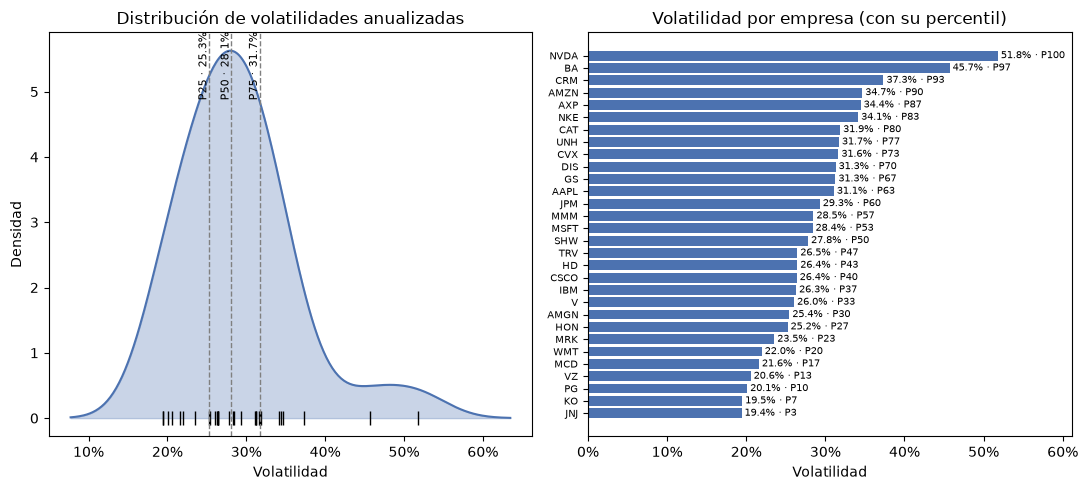

In [18]:
pct = vol.rank(pct=True).round(2)                            
fmt = lambda x, _: f"{x:.0%}"

def grafico(rojas=()):
    """Curva de distribución + barras por empresa. Las empresas de `rojas` salen en rojo."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

    h = 1.06 * vol.std() * len(vol) ** -0.2                
    x = np.linspace(vol.min() - 3 * h, vol.max() + 3 * h, 300)
    dens = np.exp(-0.5 * ((x[:, None] - vol.values) / h) ** 2).sum(axis=1) / (len(vol) * h * np.sqrt(2 * np.pi))
    ax1.plot(x, dens, color="#4c72b0")
    ax1.fill_between(x, dens, color="#4c72b0", alpha=0.3)
    ax1.plot(vol, np.zeros(len(vol)), "|", color="black", ms=10, clip_on=False) 
    for q in (0.25, 0.50, 0.75):
        v = vol.quantile(q)
        ax1.axvline(v, color="gray", ls="--", lw=1)
        ax1.text(v, ax1.get_ylim()[1], f"P{q*100:.0f} · {v:.1%}", rotation=90, va="top", ha="right", fontsize=8)
    ax1.set(title="Distribución de volatilidades anualizadas", xlabel="Volatilidad", ylabel="Densidad")

    ax2.barh(vol.index, vol, color=["#c44e52" if e in rojas else "#4c72b0" for e in vol.index])
    for i, (v, p) in enumerate(zip(vol, pct)):
        ax2.text(v, i, f" {v:.1%} · P{p*100:.0f}", va="center", fontsize=7)
    ax2.set(title="Volatilidad por empresa (con su percentil)", xlabel="Volatilidad")
    ax2.tick_params(axis="y", labelsize=7)
    ax2.margins(x=0.18)

    if len(rojas):                                           
        corte = vol[list(rojas)].min()
        ax1.fill_between(x, dens, where=x >= corte - 1e-9, color="#c44e52", alpha=0.5)
        for ax in (ax1, ax2):
            ax.axvline(corte, color="#c44e52", lw=1.2)

    for ax in (ax1, ax2):
        ax.xaxis.set_major_formatter(fmt)
    plt.tight_layout()
    plt.show()

grafico()

### 2.3 Corte en P83: grupos volátiles y no volátiles

VOLÁTILES (6): ['NKE', 'AXP', 'AMZN', 'CRM', 'BA', 'NVDA']
NO VOLÁTILES (24): ['JNJ', 'KO', 'PG', 'VZ', 'MCD', 'WMT', 'MRK', 'HON', 'AMGN', 'V', 'IBM', 'CSCO', 'HD', 'TRV', 'SHW', 'MSFT', 'MMM', 'JPM', 'AAPL', 'GS', 'DIS', 'CVX', 'UNH', 'CAT']


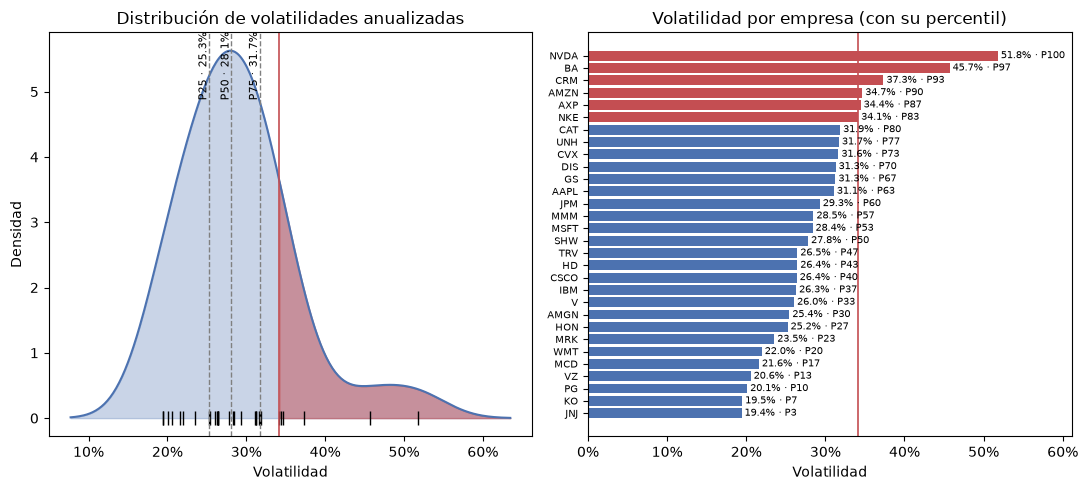

In [19]:
CORTE_PCT = 0.83   

tabla = vol.rename("volatilidad").to_frame().assign(volatil=pct >= CORTE_PCT)
volatiles = tabla.index[tabla["volatil"]].tolist()
no_volatiles = tabla.index[~tabla["volatil"]].tolist()
print(f"VOLÁTILES ({len(volatiles)}): {volatiles}")
print(f"NO VOLÁTILES ({len(no_volatiles)}): {no_volatiles}")

grafico(volatiles)  

## 3. Métricas y puntuación de cada empresa

Calculamos rentabilidad, Sharpe, Sortino y drawdown de cada empresa con la tasa libre de riesgo del enunciado (1 %). La puntuación es la media de sus 4 percentiles dentro de su grupo, volátiles o no volátiles.

In [20]:
# Tasa libre de riesgo: 1 % (0,01)
rf = 0.01
print(f"r_f: {rf:.2%}")

# Métricas anualizadas por empresa
mu = rent.mean() * DIAS_ANIO                                             # rentabilidad anualizada
caidas = np.minimum(rent - rf / DIAS_ANIO, 0)                            # solo las rentabilidades por debajo de r_f (MAR)
vol_caidas = np.sqrt((caidas**2).mean() * DIAS_ANIO)                     # volatilidad solo de las caídas
acum = (1 + rent.fillna(0)).cumprod()                                    # rentabilidad acumulada

tabla = tabla.assign(
    rentabilidad=mu,
    sharpe=(mu - rf) / vol,
    sortino=(mu - rf) / vol_caidas,
    drawdown=(acum / acum.cummax() - 1).min(),                           # mayor caída desde un máximo, en todo el histórico
)

r_f: 1.00%


### 3.1 Ranking de volátiles y no volátiles

In [21]:
# Puntuación: media de 4 percentiles, calculados dentro de cada grupo (volátiles y no volátiles)
# En las 4 métricas más es mejor (el drawdown es negativo, así que puntúa más el que está más cerca de 0)
tabla["puntuacion"] = (
    tabla.groupby("volatil")[["sharpe", "sortino", "drawdown", "rentabilidad"]]
    .rank(pct=True)
    .mean(axis=1)
)

# Un ranking por grupo: de cada uno saldrán las mejores (2 no volátiles y 1 volátil)
cols = ["volatilidad", "rentabilidad", "sharpe", "sortino", "drawdown", "puntuacion"]
ranking_volatiles = tabla[tabla["volatil"]][cols].sort_values("puntuacion", ascending=False)
ranking_no_volatiles = tabla[~tabla["volatil"]][cols].sort_values("puntuacion", ascending=False)

print("VOLÁTILES")
display(ranking_volatiles.round(3))
print("NO VOLÁTILES")
display(ranking_no_volatiles.round(3))

VOLÁTILES


,volatilidad,rentabilidad,sharpe,sortino,drawdown,puntuacion
symbol,,,,,,
AXP,0.344,0.244,0.679,1.036,-0.496,0.875
NVDA,0.518,0.577,1.096,1.639,-0.663,0.875
AMZN,0.347,0.193,0.527,0.769,-0.561,0.708
CRM,0.373,0.160,0.401,0.582,-0.586,0.542
NKE,0.341,0.050,0.118,0.167,-0.685,0.333
BA,0.457,0.038,0.062,0.090,-0.779,0.167


NO VOLÁTILES


,volatilidad,rentabilidad,sharpe,sortino,drawdown,puntuacion
symbol,,,,,,
WMT,0.220,0.221,0.963,1.451,-0.257,0.938
AAPL,0.311,0.284,0.882,1.298,-0.385,0.885
MSFT,0.284,0.256,0.866,1.273,-0.371,0.875
CAT,0.319,0.245,0.736,1.072,-0.395,0.771
GS,0.313,0.248,0.760,1.126,-0.456,0.729
PG,0.201,0.133,0.611,0.878,-0.238,0.708
IBM,0.263,0.179,0.643,0.919,-0.390,0.708
V,0.260,0.166,0.599,0.866,-0.364,0.708
JPM,0.293,0.212,0.691,1.019,-0.436,0.667


## 4. Tríos candidatos: 2 no volátiles + 1 volátil

Combinamos las 8 mejores no volátiles, de 2 en 2, con los 4 mejores volátiles: 28 × 4 = 112 tríos. Todos van a pesos iguales (1/3 cada uno, rebalanceado a diario) y ordenados por Sharpe.

In [22]:
from itertools import combinations
seguras = ranking_no_volatiles.index[:8]
volatiles_top = ranking_volatiles.index[:4]

def metricas(r):
    """Métricas anualizadas de una serie de rentabilidades diarias."""
    mu, sigma = r.mean() * DIAS_ANIO, r.std() * np.sqrt(DIAS_ANIO)
    caidas = np.minimum(r - rf / DIAS_ANIO, 0)
    acum = (1 + r).cumprod()
    return pd.Series({
        "rentabilidad": mu,
        "volatilidad": sigma,
        "sharpe": (mu - rf) / sigma,
        "sortino": (mu - rf) / np.sqrt((caidas**2).mean() * DIAS_ANIO),
        "drawdown": (acum / acum.cummax() - 1).min(),
    })

# Cartera a pesos iguales (1/3).
trios = pd.DataFrame({
    " + ".join([*par, v]): metricas(rent[[*par, v]].mean(axis=1).dropna())
    for par in combinations(seguras, 2)
    for v in volatiles_top
}).T.sort_values(["sharpe", "volatilidad"], ascending=[False, True])   

print(f"{len(trios)} tríos evaluados")
display(trios.head(8).round(3)) 

112 tríos evaluados


,rentabilidad,volatilidad,sharpe,sortino,drawdown
WMT + PG + NVDA,0.311,0.231,1.299,1.951,-0.332
WMT + CAT + NVDA,0.348,0.264,1.280,1.898,-0.327
WMT + IBM + NVDA,0.326,0.248,1.273,1.892,-0.331
WMT + GS + NVDA,0.349,0.267,1.268,1.876,-0.353
WMT + AAPL + NVDA,0.361,0.278,1.261,1.873,-0.354
WMT + MSFT + NVDA,0.352,0.276,1.236,1.839,-0.382
WMT + V + NVDA,0.322,0.258,1.209,1.798,-0.329
CAT + PG + NVDA,0.318,0.257,1.198,1.768,-0.347


### 4.1 Correlaciones del trío nº 1 por Sharpe total

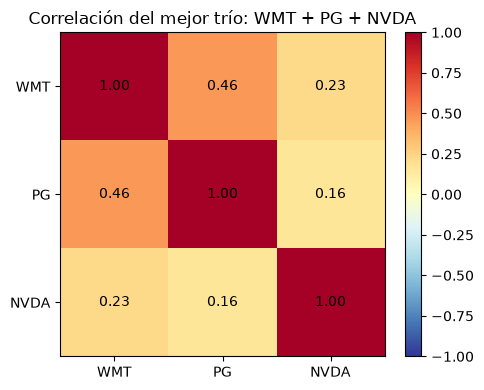

In [23]:
# Matriz de correlación (sobre rentabilidades) del mejor trío
mejor = trios.index[0].split(" + ")
corr = rent[mejor].corr()

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, cmap="RdYlBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(3), mejor)
ax.set_yticks(range(3), mejor)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im)
ax.set_title(f"Correlación del mejor trío: {' + '.join(mejor)}")
plt.tight_layout()
plt.show()

### 4.2 Tríos con los 3 sectores distintos

In [24]:
yahoo = {t: yf.Ticker(t).info.get("sector") for t in sorted(precios.columns)}
filas = [f'"{t}": "{s}"' for t, s in yahoo.items()]
print("{\n" + ",\n".join("    " + ", ".join(filas[i:i + 4]) for i in range(0, len(filas), 4)) + ",\n}")

{
    "AAPL": "Technology", "AMGN": "Healthcare", "AMZN": "Consumer Cyclical", "AXP": "Financial Services",
    "BA": "Industrials", "CAT": "Industrials", "CRM": "Technology", "CSCO": "Technology",
    "CVX": "Energy", "DIS": "Communication Services", "GS": "Financial Services", "HD": "Consumer Cyclical",
    "HON": "Industrials", "IBM": "Technology", "JNJ": "Healthcare", "JPM": "Financial Services",
    "KO": "Consumer Defensive", "MCD": "Consumer Cyclical", "MMM": "Industrials", "MRK": "Healthcare",
    "MSFT": "Technology", "NKE": "Consumer Cyclical", "NVDA": "Technology", "PG": "Consumer Defensive",
    "SHW": "Basic Materials", "TRV": "Financial Services", "UNH": "Healthcare", "V": "Financial Services",
    "VZ": "Communication Services", "WMT": "Consumer Defensive",
}


In [25]:
sector = {
    "AAPL": "Technology", "AMGN": "Healthcare", "AMZN": "Consumer Cyclical", "AXP": "Financial Services",
    "BA": "Industrials", "CAT": "Industrials", "CRM": "Technology", "CSCO": "Technology",
    "CVX": "Energy", "DIS": "Communication Services", "GS": "Financial Services", "HD": "Consumer Cyclical",
    "HON": "Industrials", "IBM": "Technology", "JNJ": "Healthcare", "JPM": "Financial Services",
    "KO": "Consumer Defensive", "MCD": "Consumer Cyclical", "MMM": "Industrials", "MRK": "Healthcare",
    "MSFT": "Technology", "NKE": "Consumer Cyclical", "NVDA": "Technology", "PG": "Consumer Defensive",
    "SHW": "Basic Materials", "TRV": "Financial Services", "UNH": "Healthcare", "V": "Financial Services",
    "VZ": "Communication Services", "WMT": "Consumer Defensive",
}

# Ranking con empresas de sectores diferentes
trios_3s = trios[[len({sector[e] for e in t.split(" + ")}) == 3 for t in trios.index]]
print(f"{len(trios_3s)} de {len(trios)} tríos con 3 sectores distintos")
trios_3s.head(8).round(3)

50 de 112 tríos con 3 sectores distintos


,rentabilidad,volatilidad,sharpe,sortino,drawdown
WMT + CAT + NVDA,0.348,0.264,1.280,1.898,-0.327
WMT + GS + NVDA,0.349,0.267,1.268,1.876,-0.353
WMT + V + NVDA,0.322,0.258,1.209,1.798,-0.329
CAT + PG + NVDA,0.318,0.257,1.198,1.768,-0.347
GS + PG + NVDA,0.319,0.261,1.186,1.748,-0.372
CAT + GS + NVDA,0.357,0.309,1.123,1.643,-0.382
PG + V + NVDA,0.292,0.254,1.112,1.645,-0.359
CAT + V + NVDA,0.329,0.292,1.093,1.594,-0.360


### 4.3 Correlaciones del mejor trío con 3 sectores distintos (por Sharpe total)

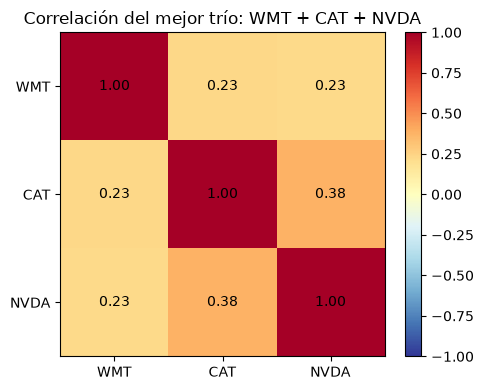

In [26]:
mejor = trios_3s.index[0].split(" + ")
corr = rent[mejor].corr()

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, cmap="RdYlBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(3), mejor)
ax.set_yticks(range(3), mejor)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im)
ax.set_title(f"Correlación del mejor trío: {' + '.join(mejor)}")
plt.tight_layout()
plt.show()